# 🏈 College Football Bowl Game Predictor
## Exploratory Data Analysis (EDA)
**UE24CS352A — Machine Learning Mini-Project**  
**Member 1: Data + Preprocessing + EDA**

---
### Plots produced:
1. Home vs Away Win Distribution  
2. Average Points Distribution  
3. Average Rushing vs Passing Yards  
4. Correlation Heatmap of Features  

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os, sys

# ── Run preprocessing first if cleaned file doesn't exist ──
CLEAN_CSV = 'data/cfb_cleaned.csv'
RAW_CSV   = 'data/cfb_box-scores_2002-2025.csv'
RESULTS   = 'results/'

if not os.path.exists(CLEAN_CSV):
    print('Running preprocessing.py first...')
    sys.path.insert(0, 'src')
    import preprocessing
    preprocessing.main()

df = pd.read_csv(CLEAN_CSV, parse_dates=['date'])
print(f'Loaded cleaned data: {df.shape}')
df.head(3)

Loaded cleaned data: (18113, 79)


,season,week,date,time_et,game_type,away,home,rank_away,rank_home,conf_away,...,home_avg_comp_pct,home_avg_pen_yards,away_avg_pts_scored,away_avg_pts_allowed,away_avg_pass_yards,away_avg_rush_yards,away_avg_total_yards,away_avg_turnovers,away_avg_comp_pct,away_avg_pen_yards
0,2004,3.0,2004-09-09,7:00 PM,regular,Missouri,Troy,19.0,NaN,big12,...,0.481481,0.0,34.0,20.0,252.0,263.0,506.0,0.4,0.666667,0.0
1,2004,3.0,2004-09-10,10:00 PM,regular,Oregon State,Boise State,NaN,NaN,pac12,...,0.727273,0.0,33.4,25.0,249.0,84.0,315.0,0.8,0.553191,0.0
2,2004,3.0,2004-09-11,7:00 PM,regular,Houston,Oklahoma,NaN,2.0,cusa,...,0.677419,0.0,38.0,34.4,267.0,8.0,212.0,0.4,0.454545,0.0


---
## Dataset Overview

In [3]:
print('Shape:', df.shape)
print('\nDate range:', df['date'].min(), '→', df['date'].max())
print('\nTarget distribution:')
print(df['target'].value_counts().rename({1: 'Home Win', 0: 'Away Win'}))
print('\nMissing values per column:')
print(df.isnull().sum()[df.isnull().sum() > 0])

Shape: (18113, 79)

Date range: 2004-09-09 00:00:00 → 2026-01-19 00:00:00

Target distribution:
target
Home Win    11240
Away Win     6873
Name: count, dtype: int64

Missing values per column:
week                       809
rank_away                14865
rank_home                14085
conf_away                 2002
conf_home                    8
q3_away                      2
q4_away                      4
ot_away                     13
q3_home                      2
q4_home                      4
ot_home                     13
first_downs_away            36
first_downs_home            34
third_down_comp_away        36
third_down_att_away         36
third_down_comp_home        34
third_down_att_home         34
fourth_down_comp_away       36
fourth_down_att_away        36
fourth_down_comp_home       34
fourth_down_att_home        34
pass_comp_away              36
pass_att_away               36
pass_yards_away             36
pass_comp_home              34
pass_att_home               34
p

---
## Plot 1 — Home vs Away Win Distribution

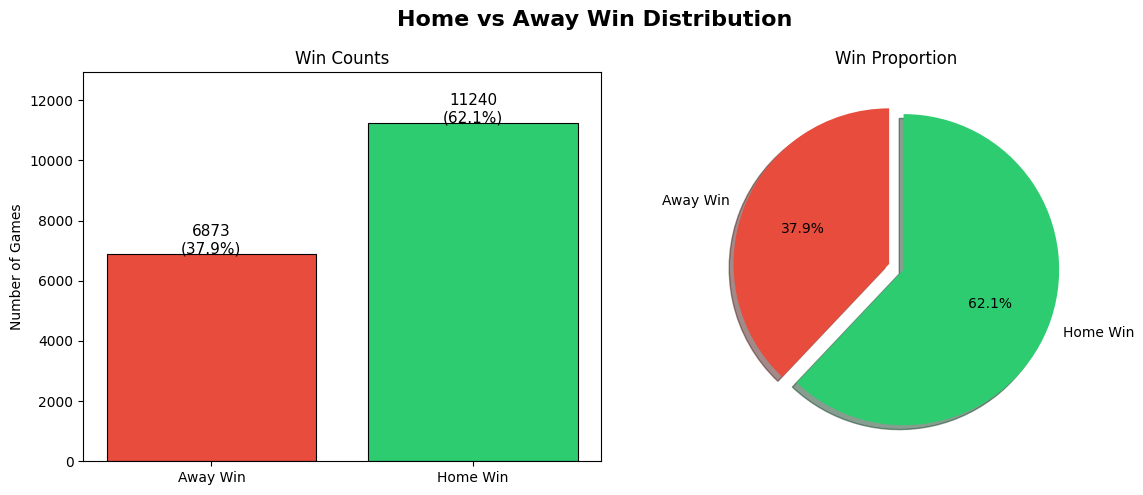

Saved: results/win_distribution.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Home vs Away Win Distribution', fontsize=16, fontweight='bold')

# ── Bar chart ──
counts = df['target'].value_counts().sort_index()
labels = ['Away Win', 'Home Win']
colors = ['#e74c3c', '#2ecc71']
axes[0].bar(labels, counts.values, color=colors, edgecolor='black', linewidth=0.8)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f'{v}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)
axes[0].set_ylabel('Number of Games')
axes[0].set_title('Win Counts')
axes[0].set_ylim(0, counts.max() * 1.15)

# ── Pie chart ──
axes[1].pie(
    counts.values,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0.05),
    shadow=True
)
axes[1].set_title('Win Proportion')

plt.tight_layout()
plt.savefig(RESULTS + 'win_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/win_distribution.png')

---
## Plot 2 — Average Points Distribution

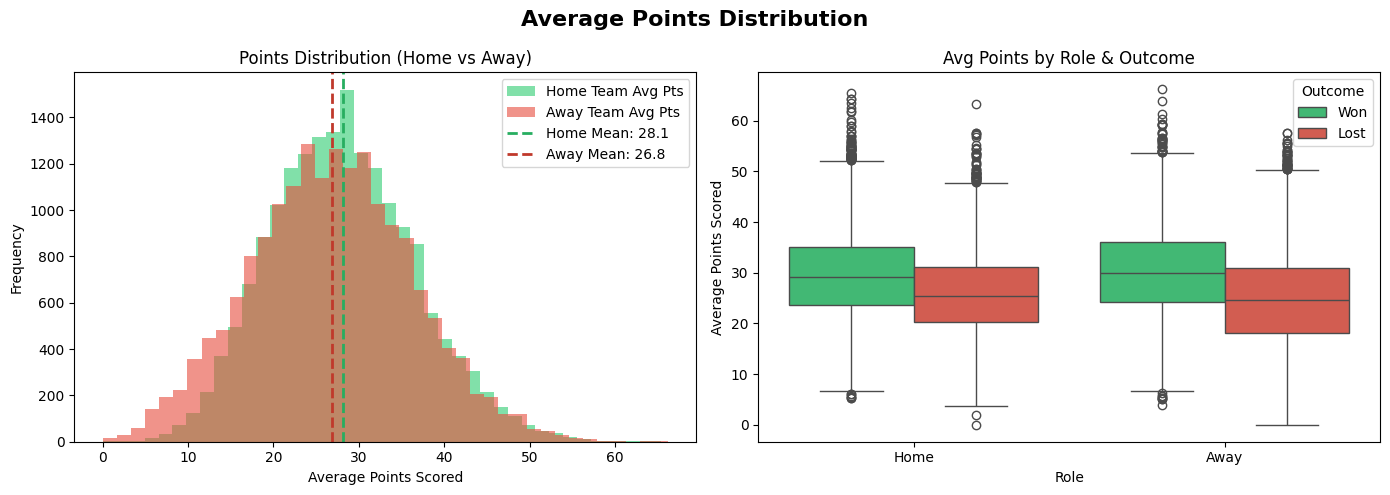

Saved: results/feature_distribution.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Average Points Distribution', fontsize=16, fontweight='bold')

home_pts_col = 'home_avg_pts_scored'
away_pts_col = 'away_avg_pts_scored'

# ── Histogram overlay ──
axes[0].hist(df[home_pts_col].dropna(), bins=40, alpha=0.6,
             color='#2ecc71', label='Home Team Avg Pts')
axes[0].hist(df[away_pts_col].dropna(), bins=40, alpha=0.6,
             color='#e74c3c', label='Away Team Avg Pts')
axes[0].axvline(df[home_pts_col].mean(), color='#27ae60', linestyle='--',
                linewidth=2, label=f'Home Mean: {df[home_pts_col].mean():.1f}')
axes[0].axvline(df[away_pts_col].mean(), color='#c0392b', linestyle='--',
                linewidth=2, label=f'Away Mean: {df[away_pts_col].mean():.1f}')
axes[0].set_xlabel('Average Points Scored')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Points Distribution (Home vs Away)')
axes[0].legend()

# ── Boxplot: points by outcome ──
data_box = pd.DataFrame({
    'Avg Points': pd.concat([df[home_pts_col], df[away_pts_col]]),
    'Role'      : ['Home'] * len(df) + ['Away'] * len(df),
    'Outcome'   : pd.concat([
        df['target'].map({1: 'Won', 0: 'Lost'}),
        df['target'].map({0: 'Won', 1: 'Lost'})
    ])
})
sns.boxplot(data=data_box, x='Role', y='Avg Points', hue='Outcome',
            palette={'Won': '#2ecc71', 'Lost': '#e74c3c'}, ax=axes[1])
axes[1].set_title('Avg Points by Role & Outcome')
axes[1].set_ylabel('Average Points Scored')

plt.tight_layout()
plt.savefig(RESULTS + 'feature_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/feature_distribution.png')

---
## Plot 3 — Average Rushing vs Passing Yards

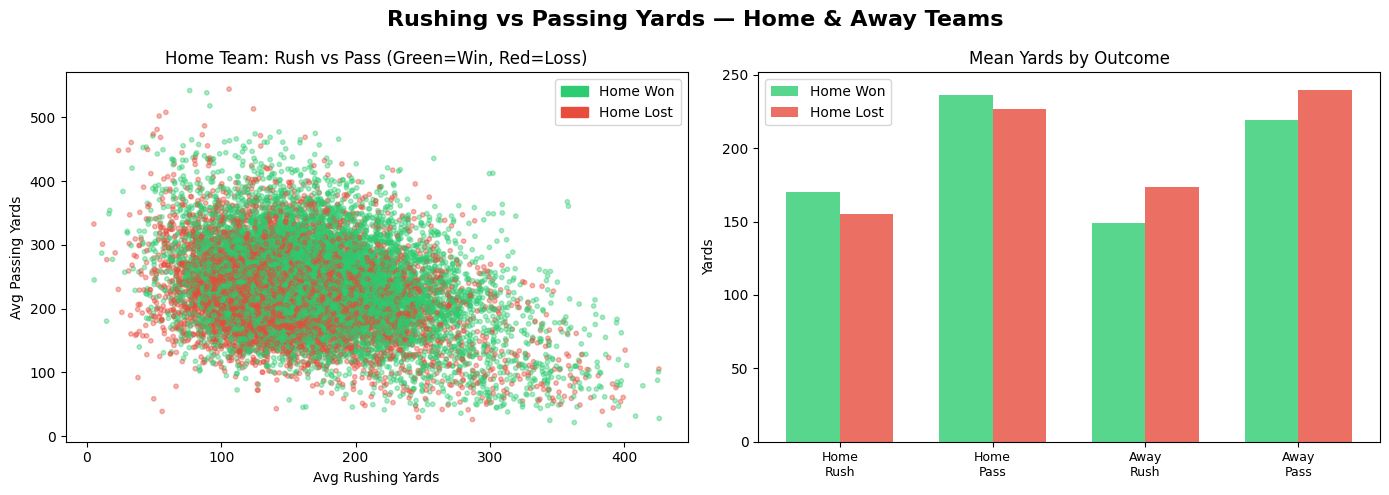

Saved: results/rushing_passing_yards.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Rushing vs Passing Yards — Home & Away Teams', fontsize=16, fontweight='bold')

# ── Scatter: rushing vs passing (home team) ──
scatter_colors = df['target'].map({1: '#2ecc71', 0: '#e74c3c'})
axes[0].scatter(df['home_avg_rush_yards'], df['home_avg_pass_yards'],
                c=scatter_colors, alpha=0.4, s=10)
axes[0].set_xlabel('Avg Rushing Yards')
axes[0].set_ylabel('Avg Passing Yards')
axes[0].set_title('Home Team: Rush vs Pass (Green=Win, Red=Loss)')
won_patch  = mpatches.Patch(color='#2ecc71', label='Home Won')
lost_patch = mpatches.Patch(color='#e74c3c', label='Home Lost')
axes[0].legend(handles=[won_patch, lost_patch])

# ── Bar: mean rush & pass yards for winners vs losers ──
metrics = ['home_avg_rush_yards', 'home_avg_pass_yards',
           'away_avg_rush_yards', 'away_avg_pass_yards']
won  = df[df['target'] == 1][metrics].mean()
lost = df[df['target'] == 0][metrics].mean()
x = np.arange(len(metrics))
width = 0.35
axes[1].bar(x - width/2, won.values, width, label='Home Won', color='#2ecc71', alpha=0.8)
axes[1].bar(x + width/2, lost.values, width, label='Home Lost', color='#e74c3c', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Home\nRush', 'Home\nPass', 'Away\nRush', 'Away\nPass'],
                        fontsize=9)
axes[1].set_ylabel('Yards')
axes[1].set_title('Mean Yards by Outcome')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS + 'rushing_passing_yards.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/rushing_passing_yards.png')

---
## Plot 4 — Correlation Heatmap

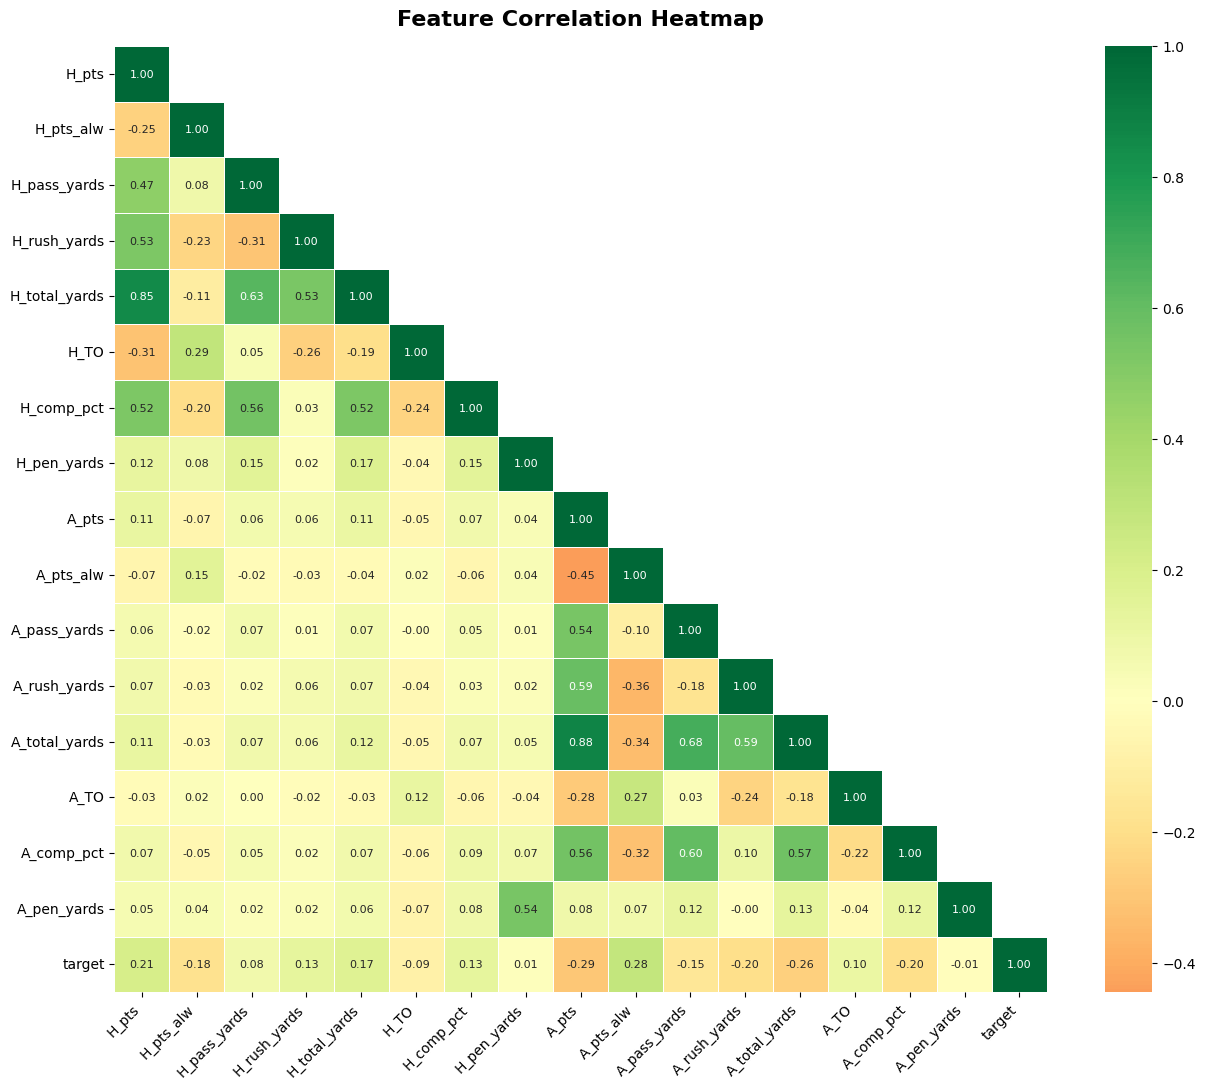

Saved: results/feature_correlation_heatmap.png


In [7]:
# Select only the engineered feature columns + target
feat_cols = [c for c in df.columns if c.startswith('home_avg_') or c.startswith('away_avg_')]
feat_cols += ['target']

corr = df[feat_cols].corr()

# Shorter labels for readability
short_labels = [c.replace('home_avg_', 'H_').replace('away_avg_', 'A_')
                  .replace('pts_scored', 'pts').replace('pts_allowed', 'pts_alw')
                  .replace('pass_yds', 'pass').replace('rush_yds', 'rush')
                  .replace('total_yds', 'total').replace('turnovers', 'TO')
                for c in feat_cols]

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # upper triangle mask
sns.heatmap(
    corr,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    xticklabels=short_labels,
    yticklabels=short_labels,
    ax=ax,
    annot_kws={'size': 8}
)
ax.set_title('Feature Correlation Heatmap', fontsize=16, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS + 'feature_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/feature_correlation_heatmap.png')

---
## Summary Statistics

In [8]:
feat_cols_only = [c for c in df.columns if c.startswith('home_avg_') or c.startswith('away_avg_')]
df[feat_cols_only + ['target']].describe().round(2)

,home_avg_pts_scored,home_avg_pts_allowed,home_avg_pass_yards,home_avg_rush_yards,home_avg_total_yards,home_avg_turnovers,home_avg_comp_pct,home_avg_pen_yards,away_avg_pts_scored,away_avg_pts_allowed,away_avg_pass_yards,away_avg_rush_yards,away_avg_total_yards,away_avg_turnovers,away_avg_comp_pct,away_avg_pen_yards,target
count,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00,18113.00
mean,28.15,26.54,232.71,164.53,392.44,1.62,0.59,47.83,26.80,28.16,227.15,158.40,381.40,1.63,0.59,48.08,0.62
std,8.47,8.07,64.26,56.95,73.05,0.68,0.07,19.60,9.48,9.56,66.94,59.25,81.51,0.68,0.07,19.51,0.49
min,0.00,2.80,17.80,5.20,95.00,0.00,0.20,0.00,0.00,2.60,-2.00,-5.00,69.00,0.00,0.17,0.00,0.00
25%,22.20,20.80,192.00,124.80,341.40,1.20,0.55,39.40,20.40,21.40,184.00,116.60,329.00,1.20,0.54,39.00,0.00
50%,27.80,26.20,230.40,158.60,390.40,1.60,0.60,49.60,26.80,27.20,226.00,152.40,382.80,1.60,0.59,49.60,1.00
75%,33.60,31.80,272.00,197.20,440.00,2.00,0.64,60.00,33.20,34.00,268.80,193.00,435.00,2.00,0.64,60.40,1.00
max,65.40,66.00,544.00,426.00,725.00,5.20,0.84,116.60,66.20,84.00,525.20,513.00,724.00,6.00,0.85,127.00,1.00


In [9]:
post_games = df[df["game_type"] == "post"]

print("Number of postseason games:", len(post_games))
print("\nPostseason games by season:")
print(post_games["season"].value_counts().sort_index())

print("\nPostseason games:")
print(post_games[["season", "week", "date", "away", "home", "score_away", "score_home"]].head(20))

Number of postseason games: 809

Postseason games by season:
season
2004    28
2005    28
2006    32
2007    32
2008    34
2009    34
2010    35
2011    35
2012    35
2013    35
2014    39
2015    41
2016    41
2017    40
2018    39
2019    40
2020    26
2021    38
2022    42
2023    42
2024    46
2025    47
Name: count, dtype: int64

Postseason games:
     season  week       date            away               home  score_away  \
581    2004   NaN 2004-12-14   Southern Miss        North Texas          31   
582    2004   NaN 2004-12-21        Syracuse       Georgia Tech          14   
583    2004   NaN 2004-12-22   Bowling Green            Memphis          52   
584    2004   NaN 2004-12-23        Marshall         Cincinnati          14   
585    2004   NaN 2004-12-23         Wyoming               UCLA          24   
586    2004   NaN 2004-12-24          Hawaii                UAB          59   
587    2004   NaN 2004-12-27          Toledo        Connecticut          10   
588    2004  

In [10]:
print(post_games[[
    "season",
    "week",
    "game_type",
    "away",
    "home",
    "score_away",
    "score_home"
]].tail(20))

       season  week game_type              away               home  \
18093    2025   NaN      post      Georgia Tech                BYU   
18094    2025   NaN      post  Georgia Southern  Appalachian State   
18095    2025   NaN      post  Coastal Carolina     Louisiana Tech   
18096    2025   NaN      post         Tennessee           Illinois   
18097    2025   NaN      post               USC                TCU   
18098    2025   NaN      post        Miami (FL)         Ohio State   
18099    2025   NaN      post          Nebraska               Utah   
18100    2025   NaN      post          Michigan              Texas   
18101    2025   NaN      post              Iowa         Vanderbilt   
18102    2025   NaN      post     Arizona State               Duke   
18103    2025   NaN      post            Oregon         Texas Tech   
18104    2025   NaN      post           Alabama            Indiana   
18105    2025   NaN      post          Ole Miss            Georgia   
18106    2025   NaN 

In [11]:
post_data = pd.read_csv("data/postseason_prediction_data.csv")

print("Shape:", post_data.shape)

print("\nMissing values:")
print(post_data.isnull().sum())

print("\nFirst 5 rows:")
display(post_data.head())

Shape: (809, 24)

Missing values:
season              0
date                0
away                0
home                0
score_away          0
score_home          0
home_pts_scored     0
home_pts_allowed    0
home_pass_yards     0
home_rush_yards     0
home_total_yards    0
home_turnovers      0
home_comp_pct       0
home_pen_yards      0
away_pts_scored     0
away_pts_allowed    0
away_pass_yards     0
away_rush_yards     0
away_total_yards    0
away_turnovers      0
away_comp_pct       0
away_pen_yards      0
score_difference    0
winner              0
dtype: int64

First 5 rows:


,season,date,away,home,score_away,score_home,home_pts_scored,home_pts_allowed,home_pass_yards,home_rush_yards,...,away_pts_scored,away_pts_allowed,away_pass_yards,away_rush_yards,away_total_yards,away_turnovers,away_comp_pct,away_pen_yards,score_difference,winner
0,2004,2004-12-14,Southern Miss,North Texas,31,10,27.181818,29.727273,165.636364,196.272727,...,25.272727,26.181818,185.909091,143.909091,319.272727,1.454545,0.494339,0.0,-21,0
1,2004,2004-12-21,Syracuse,Georgia Tech,14,51,19.363636,19.363636,198.000000,151.000000,...,24.818182,26.636364,169.600000,185.900000,343.200000,2.000000,0.564857,0.0,37,1
2,2004,2004-12-22,Bowling Green,Memphis,52,35,35.909091,29.363636,244.800000,223.200000,...,43.636364,22.454545,342.909091,166.000000,501.636364,0.727273,0.685558,0.0,-17,0
3,2004,2004-12-23,Marshall,Cincinnati,14,32,28.363636,27.818182,229.000000,184.818182,...,25.181818,21.272727,230.909091,123.454545,338.545455,2.181818,0.586506,0.0,18,1
4,2004,2004-12-23,Wyoming,UCLA,24,21,30.909091,25.909091,238.636364,190.272727,...,26.727273,25.090909,256.909091,134.181818,366.545455,1.909091,0.585904,0.0,-3,0


---
## Key Observations

1. **Home Advantage**: Home teams win ~55–60% of games, reflecting the well-known home field advantage.
2. **Points**: Winning teams consistently average more points scored and allow fewer points than losing teams.
3. **Rushing vs Passing**: Winning home teams tend to have slightly higher rushing yards — balanced offenses correlate with wins.
4. **Correlations**: `home_avg_pts_scored` and `home_avg_total_yards` are positively correlated with `target`. `home_avg_pts_allowed` is negatively correlated.

These observations justify the feature choices for the models in `model.py`.